# Activity 2: Simple House Price Prediction using Linear Regression

**Dataset:** House Prices Dataset
**File:** `house-prices.csv`
**Source:** PASTE_DATASET_SOURCE_LINK_HERE

This activity uses a house price dataset containing **128 records and 8 columns**. The dataset includes features such as house size in square feet (`SqFt`), number of bedrooms, bathrooms, offers, brick type and neighbourhood.

The objective is to predict the **Price** of a house using **SqFt** as the input feature. `Price` is a continuous numerical variable, which makes it suitable for a Linear Regression model.

In [1]:
import pandas as pd

df = pd.read_csv("house-prices.csv")
df.head()

,Home,Price,SqFt,Bedrooms,Bathrooms,Offers,Brick,Neighborhood
0,1,114300,1790,2,2,2,No,East
1,2,114200,2030,4,2,3,No,East
2,3,114800,1740,3,2,1,No,East
3,4,94700,1980,3,2,3,No,East
4,5,119800,2130,3,3,3,No,East


In [2]:
print(df.shape)
print(df.dtypes)
print(df.isnull().sum())
print("Duplicates:", df.duplicated().sum())
df.describe()

(128, 8)
Home            int64
Price           int64
SqFt            int64
Bedrooms        int64
Bathrooms       int64
Offers          int64
Brick             str
Neighborhood      str
dtype: object
Home            0
Price           0
SqFt            0
Bedrooms        0
Bathrooms       0
Offers          0
Brick           0
Neighborhood    0
dtype: int64
Duplicates: 0


,Home,Price,SqFt,Bedrooms,Bathrooms,Offers
count,128.000000,128.000000,128.000000,128.000000,128.000000,128.000000
mean,64.500000,130427.343750,2000.937500,3.023438,2.445312,2.578125
std,37.094474,26868.770371,211.572431,0.725951,0.514492,1.069324
min,1.000000,69100.000000,1450.000000,2.000000,2.000000,1.000000
25%,32.750000,111325.000000,1880.000000,3.000000,2.000000,2.000000
50%,64.500000,125950.000000,2000.000000,3.000000,2.000000,3.000000
75%,96.250000,148250.000000,2140.000000,3.000000,3.000000,3.000000
max,128.000000,211200.000000,2590.000000,5.000000,4.000000,6.000000


### Dataset Inspection

The dataset contains **128 rows and 8 columns**. The numerical columns are `Price`, `SqFt`, `Bedrooms`, `Bathrooms` and `Offers`. The dataset also has categorical columns, `Brick` and `Neighborhood`.

The missing value check shows **no missing values**, and the duplicate check shows **0 duplicate records**. Therefore, no data cleaning was required.

**Note:** The `Home` column is only a record identifier, so it is not used as a feature.

In [3]:
X = df[["SqFt"]]
y = df["Price"]

### Feature and Target Selection

- **Input feature (X):** `SqFt`
- **Target variable (y):** `Price`

`SqFt` was selected because the size of a house can be related to its price. Larger houses generally tend to cost more, although other factors can also affect the final price.

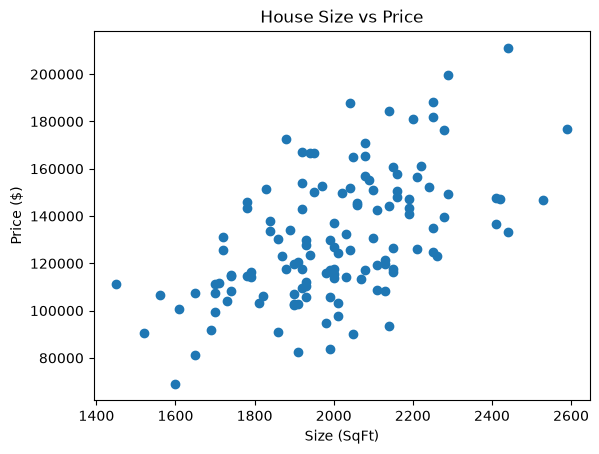

In [4]:
import matplotlib.pyplot as plt

plt.scatter(X, y)
plt.title("House Size vs Price")
plt.xlabel("Size (SqFt)")
plt.ylabel("Price ($)")
plt.show()

### Observation

The scatter plot shows a generally **positive relationship** between house size and price. As square footage increases, the price tends to increase.

The points are not perfectly aligned, which suggests that other factors also affect house prices. A visible relationship between two variables does not by itself prove causation.

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Train:", len(X_train), "Test:", len(X_test))

### Train-Test Split

The dataset was divided into:

- **Training data:** 102 observations
- **Testing data:** 26 observations

An **80:20 split** was used. The training data is used to learn the relationship between size and price, while the test data is kept separate to evaluate the model on unseen observations.

In [ ]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)

print("Intercept:", model.intercept_)
print("Coefficient:", model.coef_[0])
print(f"Price = {model.intercept_:.0f} + {model.coef_[0]:.2f} x SqFt")

Intercept: -17889.35664451371
Coefficient: 74.03513222844222
Price = -17889 + 74.04 x SqFt


### Linear Regression Model

The trained equation is:

**Price = -17,889.36 + 74.04 × SqFt**

The slope is about **74.04**: according to the model, each extra square foot is associated with an increase of about **$74.04** in predicted price.

The intercept is **-17,889.36**, the mathematical predicted price at 0 square feet. A house with zero area is not realistic, so the intercept is mainly part of the equation and not meant to be interpreted on its own.

In [ ]:
y_pred = model.predict(X_test)

compare = pd.DataFrame({"SqFt": X_test["SqFt"].values, "Actual": y_test.values, "Predicted": y_pred.round(0)})
compare.head(10)

,SqFt,Actual,Predicted
0,1720,125700,109451.0
1,1560,106600,97605.0
2,1920,167200,124258.0
3,1930,112300,124998.0
4,2060,145500,134623.0
5,2190,140900,144248.0
6,2080,165600,136104.0
7,1910,82300,123518.0
8,2140,184300,140546.0
9,2000,137000,130181.0


### Actual vs Predicted Values

The table compares actual prices with the prices predicted by the model on unseen test data.

Some predictions are close to the actual values, while others differ noticeably. This shows that house size alone cannot explain all the variation in house prices.

In [ ]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE :", mae)
print("MSE :", mse)
print("RMSE:", rmse)
print("R2  :", r2)

MAE : 15945.548715686047
MSE : 415765840.64103884
RMSE: 20390.33694280305
R2  : 0.2945934454247471


### Model Evaluation

The model was evaluated using MAE, MSE, RMSE and R².

- **MAE ≈ 15,945.55:** predictions differ from actual prices by about $15,946 on average.
- **MSE ≈ 415,765,840.64:** squares the errors, so larger errors are penalised more.
- **RMSE ≈ 20,390.34:** the typical prediction error, in the same units as price.
- **R² ≈ 0.295:** the model using only `SqFt` explains a limited part of the variation in price.

House size is useful for predicting price, but other features such as bedrooms, bathrooms and neighbourhood may improve the model.

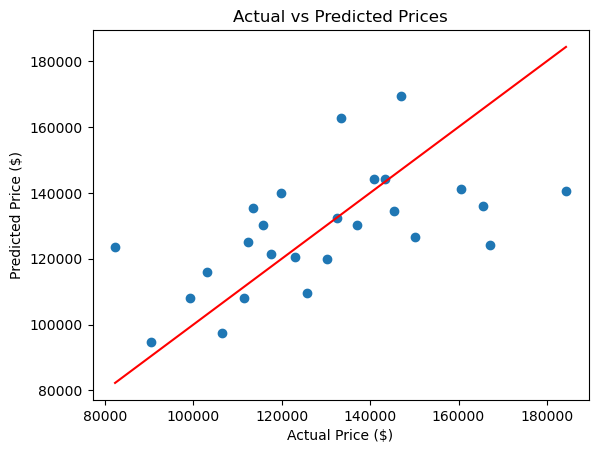

In [ ]:
plt.scatter(y_test, y_pred)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color="red")
plt.title("Actual vs Predicted Prices")
plt.xlabel("Actual Price ($)")
plt.ylabel("Predicted Price ($)")
plt.show()

### Visualization Observation

The Actual vs Predicted plot compares model predictions with true prices. The red line represents perfect predictions.

Points close to the line have small errors, while points far from it have larger errors. The spread of points away from the line shows the limits of a simple model that uses only house size.

In [ ]:
new = pd.DataFrame({"SqFt": [2000]})
print(f"Predicted price for 2000 SqFt: ${model.predict(new)[0]:,.0f}")

Predicted price for 2000 SqFt: $130,181


### New Prediction

A house of **2,000 square feet** was given as new input to the trained model. The predicted price is approximately **$130,181**.

This prediction is based only on `SqFt` and should be treated as an estimate.

### Conclusion

In this activity, a Linear Regression model was built to predict house prices from house size (`SqFt`).

The dataset was checked for missing values and duplicates, and no data-quality issues needing cleaning were found. The data was split 80:20 into training and testing sets.

The model showed a positive relationship between size and price. It was evaluated with MAE, MSE, RMSE and R². House size gives useful information for predicting price, but the model is limited because prices also depend on other factors.

A new prediction for a 2,000 sq ft house gave about **$130,181**.

Overall, the activity covered the basic workflow of data inspection, feature selection, train-test splitting, model training, prediction, evaluation and visualization.